# RNN — Gatos e cachorros
Execute uma célula por vez. Dataset local: `cats_dogs_light`.


## 1. Bibliotecas

In [1]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, ConfusionMatrixDisplay

In [2]:
IMG_SIZE = 256

## 2. Pasta do dataset

In [3]:
pasta = Path('../cats_dogs_light')
print('Pasta:', pasta.resolve())
print('Existe:', pasta.is_dir())

Pasta: C:\Users\jose.abrahim\Desktop\Curso de ML - Residencia\Deep_Model-Models_Comparision\cats_dogs_light
Existe: True


## 3. Localizar as imagens e as classes
`0 = Gato` e `1 = Cachorro`. Os nomes das pastas ou arquivos devem indicar `cat` ou `dog`.


In [4]:
arquivos = sorted([caminho for caminho in pasta.rglob('*') if caminho.suffix.lower() in ('.jpg', '.jpeg', '.png', '.bmp')])

arquivos = [caminho for caminho in arquivos if any('cat' in parte.lower() or 'dog' in parte.lower() for parte in caminho.relative_to(pasta).parts)]
rotulos = [1 if any('dog' in parte.lower() for parte in caminho.relative_to(pasta).parts) else 0 for caminho in arquivos]

print('Total de imagens:', len(arquivos))
print('Gatos:', rotulos.count(0))
print('Cachorros:', rotulos.count(1))

if not arquivos or len(set(rotulos)) != 2:
    raise ValueError('Verifique as subpastas e os nomes das imagens em cats_dogs_light.')

Total de imagens: 1310
Gatos: 655
Cachorros: 655


## 4. Separar X_train, X_test, y_train e y_test
20% das imagens são reservadas para teste, usando sempre a mesma divisão (`random_state=42`).


In [5]:
def carregar_imagem(caminho):
    imagem = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)

    if imagem is None:
        raise ValueError(f"Não foi possível carregar: {caminho}")

    imagem = cv2.resize(imagem, (IMG_SIZE, IMG_SIZE))

    return imagem[..., np.newaxis]

In [6]:
arquivos_train, arquivos_test, y_train, y_test = train_test_split(
    arquivos,
    np.array(rotulos),
    test_size=0.2,
    random_state=42,
    stratify=rotulos
)

X_train = np.array([carregar_imagem(caminho) for caminho in arquivos_train])
X_test = np.array([carregar_imagem(caminho) for caminho in arquivos_test])

print('X_train:', X_train.shape)
print('X_test:', X_test.shape)
print('y_train:', y_train.shape)
print('y_test:', y_test.shape)

X_train: (1048, 256, 256, 1)
X_test: (262, 256, 256, 1)
y_train: (1048,)
y_test: (262,)


## 5. Visualizar imagem

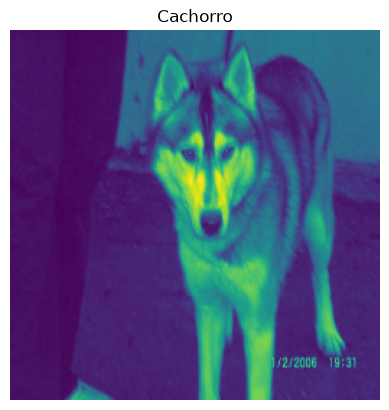

In [7]:
plt.imshow(X_train[0].astype('uint8'))
plt.title('Cachorro' if y_train[0] == 1 else 'Gato')
plt.axis('off')
plt.show()

## 6. Camadas do modelo

In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),      # Recebe imagem RGB de 64x64

    tf.keras.layers.Rescaling(1./255),            # Coloca pixels entre 0 e 1
    tf.keras.layers.Reshape((IMG_SIZE, IMG_SIZE)),           # Transforma em 64 linhas de 192 valores
    tf.keras.layers.SimpleRNN(32),                # Lê as linhas em sequência, com memória simples
    
    tf.keras.layers.Dense(64, activation='relu'),# Aprende combinações dos pixels
    tf.keras.layers.Dense(32, activation='relu'),# Aprende padrões intermediários
    tf.keras.layers.Dense(1, activation='sigmoid') # Saída
])

## 7. Compilar e treinar

In [9]:
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

historico = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 256, 256)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,473 (52.63 KB)

 Trainable params: 13,473 (52.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.5036 - loss: 0.6964 - val_accuracy: 0.4810 - val_loss: 0.6936
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5215 - loss: 0.6934 - val_accuracy: 0.4619 - val_loss: 0.6981
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.5644 - loss: 0.6869 - val_accuracy: 0.4857 - val_loss: 0.6946
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5525 - loss: 0.6852 - val_accuracy: 0.5000 - val_loss: 0.6937
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5704 - loss: 0.6829 - val_accuracy: 0.5238 - val_loss: 0.6899
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.5740 - loss: 0.6770 - val_accuracy: 0.5190 - val_loss: 0.6933
Epoch 7/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5919 - loss: 0.6758 - val_accuracy: 0.5524 - val_loss: 0.6888
Epoch 8/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5728 - loss: 0.6741 - val_accuracy: 0.4952 - v

## 8. Acurácia, precisão e matriz de confusão

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
Acurácia: 55.34 %
Precisão: 57.0 %


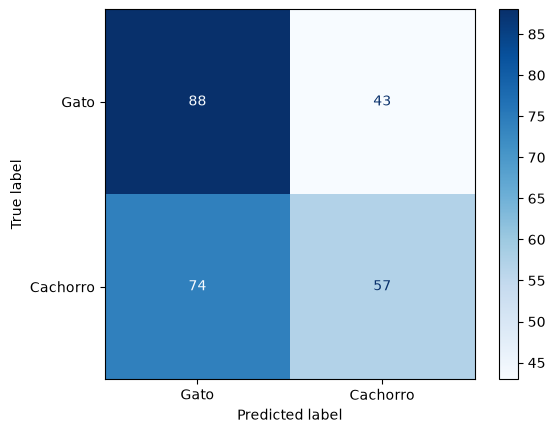

In [10]:
probabilidades = model.predict(X_test).ravel()
y_pred = (probabilidades >= 0.5).astype(int)

print('Acurácia:', round(accuracy_score(y_test, y_pred) * 100, 2), '%')
print('Precisão:', round(precision_score(y_test, y_pred, zero_division=0) * 100, 2), '%')

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Gato', 'Cachorro'], cmap='Blues'
)
plt.show()